# Ridge regression bilevel problem — conditioning sweep

Compares **PABLO**, **BOME**, **TSP**, **STABLE**, **AAL**, and **PBGD-Free** as the
condition number $\kappa(\Sigma)$ of the feature covariance varies.

$$
J(w,\theta) \triangleq \frac{1}{2N}\|X_t w - y_t\|^2 + \frac{1}{2}\theta\|w\|^2
\qquad\text{(lower: ridge regression)}
$$
$$
F(w,\theta) \triangleq \frac{1}{2M}\|X_v w - y_v\|^2
\qquad\text{(upper: validation MSE)}
$$

Data-generating process: $h_i \sim \mathcal{N}(0,\Sigma)$,
$y_i = h_i^\top w^{\rm true} + \varepsilon_i$, $\varepsilon_i \sim \mathcal{N}(0,\sigma^2)$.

The lower-level optimum is closed-form:
$w^*(\theta) = \bigl(X_t^\top X_t/N + \theta I\bigr)^{-1} X_t^\top y_t/N$.

**Protocol**
1. *Tuning phase* (4×4 init grid): for each $(\kappa,\text{method})$, try five
   multiplicative step-size scales relative to the baseline hyperparameters.
   Pick the scale minimising median final $\|w_T - w^*\| + |\theta_T - \theta^*|$.
2. *Full sweep* (10×10 init grid): run all methods with their tuned hyperparameters.
3. **Convergence metric**: first iteration $t$ at which the *median* (across all
   starts) $\|w_t - w^*\| < $ `ERR_TOL` **and** $|\theta_t - \theta^*| < $ `ERR_TOL`.
4. Save a convergence CSV + hyperparameters JSON.

In [1]:
import os, sys, json, csv, time
import numpy as np
import matplotlib.pyplot as plt

import ridge_lib
from ridge_lib import (
    run_sweep, summarise, summary_table, iters_to_converge,
    make_data, optimal_solution, upper_loss_numpy, w_star,
    METHODS,run_single
)

%load_ext autoreload
%autoreload 2

print('methods available:', ridge_lib.METHODS)
print('cpu count:', os.cpu_count())

COLOURS = {"PABLO": "#181818", "BOME": "#eb6834", "TSP": "#1baf7a", "STABLE": "#eda100",
           "AAL": "#8e5bd0", "PBGD-Free": "#d6457a"}
LINESTYLES = {"PABLO": "-", "BOME": "-", "STABLE": "-",
              "TSP": (0, (5, 2)), "AAL": (0, (5, 2)), "PBGD-Free": "--"}

methods available: ['PABLO', 'BOME', 'TSP', 'STABLE', 'AAL', 'PBGD-Free']
cpu count: 10


## Data generation — edit here

Define the covariance matrix **explicitly**.
For the conditioning sweep below a *family* of covariance matrices is generated from
`KAPPA_VALUES`, but you can also run a single experiment with `COV_SINGLE`.

In [2]:
def actual_cond_num(wo, H):                                              
      n = len(H)                                                           
      wo_col = wo.reshape(-1, 1)          # (n, 1)
      z_col  = np.zeros((n, 1))           # (n, 1)                         
      z_scalar = np.zeros((1, 1))         # (1, 1)                         
      kkt_mat = np.block([                                                 
          [H,          z_col,    H      ],   # (n, 2n+1)                   
          [z_col.T,   z_scalar, wo_col.T],  # (1, 2n+1)                   
          [H,          wo_col,   0*H    ],   # (n, 2n+1)                   
      ])                                                                   
      return np.linalg.cond(kkt_mat)       
    
# ── true regression weights (ground truth) ───────────────────────────────────
W_TRUE    = np.array([1.0, 1.0])
NOISE_STD = 0.           # label noise σ
N_TRAIN   = 1000
N_VAL     = 1000
DATA_SEED = 0             # fixed seed → same dataset for all algorithm starts

# ── single covariance for exploratory / debugging runs ───────────────────────
# Edit this directly; condition number = λ_max / λ_min
COV_SINGLE = np.array([[10.0,  0.0],
                        [ 0.0,  1.0]])   # κ = 10

DATA_KWARGS = dict(w_true=W_TRUE, n_train=N_TRAIN, n_val=N_VAL, noise_std=NOISE_STD)

data_single  = make_data(COV_SINGLE, seed=DATA_SEED, **DATA_KWARGS)
w_opt_single, theta_opt_single = optimal_solution(data_single)
print(f'κ(Σ) = {np.linalg.cond(COV_SINGLE):.1f}')
print(f'θ*   = {theta_opt_single:.5f}')
print(f'w*   = {w_opt_single}')

κ(Σ) = 10.0
θ*   = 0.00010
w*   = [0.99998977 0.99989547]


In [5]:
print(data_single.keys())
print(data_single['X_train'].shape)

dict_keys(['X_train', 'y_train', 'X_val', 'y_val'])
torch.Size([1000, 2])


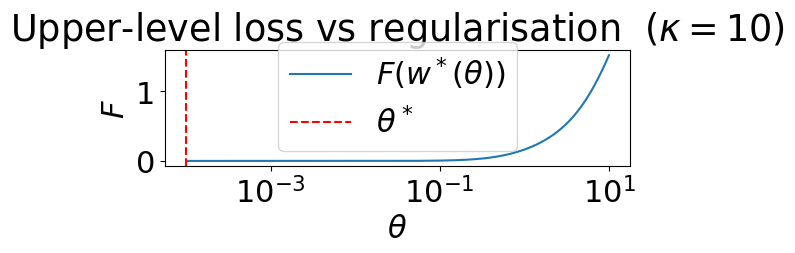

In [110]:
# ── plot F(w*(θ)) vs θ to verify the analytical solution ─────────────────────
theta_grid = np.logspace(-4, 1, 500)
F_curve    = [upper_loss_numpy(data_single, th) for th in theta_grid]

plt.figure(figsize=(6, 3))
plt.semilogx(theta_grid, F_curve, label=r'$F(w^*(\theta))$')
plt.axvline(theta_opt_single, color='r', linestyle='--', label=r'$\theta^*$')
plt.xlabel(r'$\theta$'); plt.ylabel(r'$F$')
plt.title(rf'Upper-level loss vs regularisation  ($\kappa={np.linalg.cond(COV_SINGLE):.0f}$)')
plt.legend(); plt.tight_layout(); plt.show()

## Settings — edit here

### Covariance family for the conditioning sweep
Each entry in `KAPPA_VALUES` produces `COV = diag(κ, 1)`, giving condition number κ.
Replace this with any list of explicit 2×2 covariance matrices if you prefer.

In [4]:
# ── conditioning sweep ────────────────────────────────────────────────────────
KAPPA_VALUES = [1.0, 10.0, 100.0]
COV_BY_KAPPA = {k: np.diag([k, 1.0]) for k in KAPPA_VALUES}

METHODS_RUN = ["PABLO", "BOME", "TSP", "STABLE", "AAL",]

# ── best hyperparameters at κ=1 (from run_tuning.py random search) ─────────
HPARAMS_BASE = {
    'PABLO': {'lr': 0.11531392460073672, 'alpha': 0.999, 'eps': 2.6778620778066303e-08, 'rho': 0.021806196838884323, 'lr_lambda': 0.0, 'tau': 0.0011543255252563398, 'y_rate': 0.29681039261721665, 'grad_clip': 34.90582705009883, 'lambda_bound': 6.500128038578404, 'total_steps': None},
    'BOME': {'lr': 0.27266433288309333, 'inner_lr': 0.2858284690218508, 'inner_steps': 5, 'eta': 1.6225922943522635, 'opt': 'sgd', 'barrier': 'grad_norm'},
    'TSP': {'step': 0.44261067576671054, 'eta': 0.32315575422743814, 'dual_tau': 0.0013725604575444434, 'gamma': 0.2861807398537237, 'delta': 0.0, 'p': 0.05, 'mu': 0.7, 'theta': 1.0, 'omega': 0.27606047431870767, 'lambda_init': 0.5},
    'STABLE': {'lr_w': 0.06701967959951771, 'lr_theta': 1.617255909440083, 'tau': 0.02874259435141607, 'mu_g': 0.0049539321006935606, 'C_gxy': 0.7739100644273869},
    'AAL': {'alpha': 0.016069131089736996, 'tau': 0.5217626597832874, 'L_f': 0.6404100655196386, 'L_grad_g': 1.0005832515145106, 'L_H': 0.8914694137596615, 'gamma': 0.07238197312079478, 'rho0': 0.0, 'eps': 1e-05, 'tau_decay': False},
    'PBGD-Free': {'gamma': 0.05002332004428627, 'eta': 0.5319348775260766, 'eta_gamma': 0.04559451326255957, 'K': 10},
}

STEP_KEYS = {
    "PABLO":     ["lr", "y_rate"],
    "BOME":      ["lr", "inner_lr"],
    "TSP":       ["step", "eta", "dual_tau"],
    "STABLE":    ["lr_w", "lr_theta"],
    "AAL":       ["alpha", "tau"],
    "PBGD-Free": ["eta", "eta_gamma"],
}

SCALES = [0.1, 0.3, 1.0, 3.0, 10.0]

# ── run settings ─────────────────────────────────────────────────────────────
N_ITERS      = 2000
TUNE_N       = 4
FULL_N       = 10
W0_LO, W0_HI         = -2.0, 2.0
THETA0_LO, THETA0_HI = 0.1, 5.0
ERR_TOL      = 1e-3
N_JOBS       = max(1, (os.cpu_count() or 2) - 1)

n_tune_runs = len(SCALES) * len(METHODS_RUN) * TUNE_N**2
n_full_runs = len(METHODS_RUN) * FULL_N**2
print(f'Tuning:     {n_tune_runs} runs x {N_ITERS} iters per kappa value')
print(f'Full sweep: {n_full_runs} runs x {N_ITERS} iters per kappa value')
print(f'kappa values: {KAPPA_VALUES}')


Tuning:     400 runs x 2000 iters per kappa value
Full sweep: 500 runs x 2000 iters per kappa value
kappa values: [1.0, 10.0, 100.0]


## Tuning phase

For each $(\kappa,\text{method})$, run five step-size scales on a 4×4 init grid and pick
the one minimising median final error $\|w_T - w^*\| + |\theta_T - \theta^*|$.

In [ ]:
# Tuned by run_pablo_retune.py — mixed neighbourhood + global search
# PABLO: 1000 trials × 4×4 starts × 1000 iters
# AUC = median(mean_t(||w_t - w*|| + |θ_t - θ*|))
#
#   method        κ=     1  κ=    10  κ=   100
#   PABLO           0.0219    0.0183    0.1051
#   BOME            0.0635    0.0843    0.1261
#   TSP             0.2633    0.8006    2.8320
#   STABLE          0.1813    0.1533    0.6461
#   AAL             0.0715    0.4189    1.7735
#   PBGD-Free       2.7127    2.6790    2.7175
all_hparams = {
    1.0: {
        #PABLO, STABLE, BOME, TSP, AAL tuned
        'PABLO': {'lr_w': 0.05, 'lr_theta': 0.3, 'alpha': 0.999, 'eps': 1e-6, 'rho': 0.03, 'lr_lambda': 0.05, 'tau':0.001, 'y_rate': 0.5, 'grad_clip': 10, 'lambda_bound': 0.1, 'total_steps': None},          
        "BOME":  dict(opt="sgdm", inner_steps=10, inner_lr=0.5, eta=1, lr_w=1, lr_theta=1, barrier="grad_norm"),
        "TSP": dict(step=0.5, eta=0.5,dual_tau=0.001,gamma=2.862, delta=0.01, p=1,mu=.9, theta=0.9, omega=0.9, lambda_init=0.1),
        "AAL": dict(L_f=1, L_grad_g=1.0, L_H=1, gamma=0.26, rho0=1, alpha=2e-4, eps=0.0, tau=0.1),
        "STABLE":   dict(lr_w=0.5, lr_theta=0.1, tau=0.1, mu_g=0.5, C_gxy=1),
        "PBGD-Free": dict(gamma=10.0, eta=0.5, eta_gamma=0.01, K=1), 
    },
    10.0: {
        # AUC = 0.0183
        'PABLO': {'lr': 0.06535902144200538, 'alpha': 0.999, 'eps': 2.2466002612957783e-08, 'rho': 0.031945983465740915, 'lr_lambda': 0.01, 'tau': 0.012281983295937927, 'y_rate': 1.3217709804714908, 'grad_clip': None, 'lambda_bound': 0.05, 'total_steps': None},
        # AUC = 0.0843
        'BOME': {'lr': 0.08502588525763449, 'inner_lr': 0.0033161528587830665, 'inner_steps': 50, 'eta': 0.24262775314393342, 'opt': 'rmsprop', 'barrier': 'grad_norm'},
        # AUC = 0.8006
        'TSP':  dict(step=0.1228, eta=0.01424, dual_tau=1.228,gamma=0.04281, delta=0.1, p=0.1,mu=0.09, theta=0.1, omega=0.02161, lambda_init=0.01),
        # AUC = 0.1533
        'STABLE': {'lr_w': 0.09497065974741668, 'lr_theta': 1.0050854271278689, 'tau': 1.0925973609075825, 'mu_g': 0.0013664454759693386, 'C_gxy': 1.2681989775232645},
        # AUC = 0.4189
        'AAL': {'alpha': 0.00029840338711290974, 'tau': 0.006401469767298632, 'L_f': 1.3853567882527063, 'L_grad_g': 8.62707130222255, 'L_H': 25.163165743080196, 'gamma': 0.3257315747160423, 'rho0': 0.0, 'eps': 1e-05, 'tau_decay': False},
        # AUC = 2.6790
        'PBGD-Free': {'gamma': 0.05229279888797886, 'eta': 0.005808607920730355, 'eta_gamma': 0.002145627736601652, 'K': 20},
    },
    100.0: {
        # AUC = 0.1051
        'PABLO': {'lr': 0.025405047324647212, 'alpha': 0.999, 'eps': 7.929290508964592e-08, 'rho': 0.002572756617333904, 'lr_lambda': 0.0, 'tau': 0.02596413199650779, 'y_rate': 1.8728136912569597, 'grad_clip': 12.062802697589763, 'lambda_bound': 30.348536582163618, 'total_steps': None},
        # AUC = 0.1261
        'BOME': {'lr': 0.05538592244341398, 'inner_lr': 0.008830058130472461, 'inner_steps': 20, 'eta': 0.0687627121861744, 'opt': 'rmsprop', 'barrier': 'grad_norm'},
        # AUC = 2.8320
        'TSP': {'step': 0.008880033022996793, 'eta': 0.007650083090311552, 'dual_tau': 0.005936247504020079, 'gamma': 0.021205088336831285, 'delta': 0.0, 'p': 0.01, 'mu': 0.5, 'theta': 1.0, 'omega': 0.043035036984872696, 'lambda_init': 0.5},
        # AUC = 0.6461
        'STABLE': {'lr_w': 0.016088816380765127, 'lr_theta': 0.2666261730200067, 'tau': 0.03676283654822749, 'mu_g': 0.00013185391375126907, 'C_gxy': 1.0142183998893708},
        # AUC = 1.7735
        'AAL': {'alpha': 0.00012548107446292206, 'tau': 0.12786557797487733, 'L_f': 26.628806433001994, 'L_grad_g': 35.399207140068846, 'L_H': 64.4377616947015, 'gamma': 1.652909143828194, 'rho0': 0.0, 'eps': 1e-05, 'tau_decay': False},
        # AUC = 2.7175
        'PBGD-Free': {'gamma': 0.06911564568935348, 'eta': 0.3029291551093389, 'eta_gamma': 0.001081379541785574, 'K': 10},
    },
}
tuning_log = {}



## Full sweep — 10×10 init grid with tuned hyperparameters

κ(Σ) ≈ 1.0;  3×3 = 9 starts;  200 iters;  9 total runs
dict_keys(['TSP'])


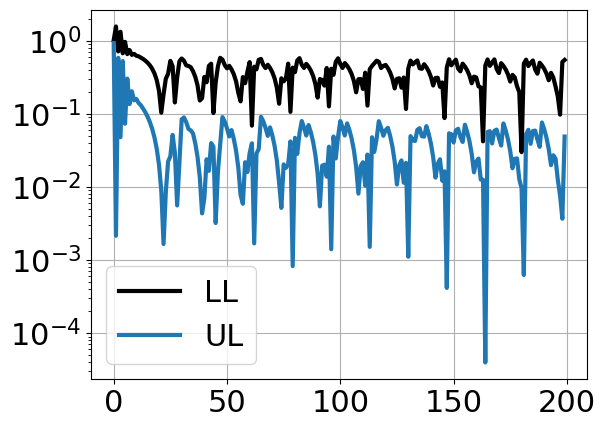

In [ ]:

m = 'TSP'
cov = COV_BY_KAPPA[1]
n_iters = 200
hparams = {m: dict(step=0.5, eta=0.5,dual_tau=0.001,gamma=2.862, delta=0.01, p=1,mu=.9, theta=0.9, omega=0.9, lambda_init=0.1)}
# r = run_single(method, hparams, cov, -0.4, 0.4, 1000, 0, DATA_KWARGS)
r = run_sweep(configs=hparams,cov=cov,
              w0_hi=W0_HI, w0_lo=W0_LO,w0_n=3,theta0_n=3,n_iters=n_iters,
              theta0_hi=THETA0_HI,theta0_lo=THETA0_LO,
              data_seed=0,data_kwargs= DATA_KWARGS,)
print(r.keys())

plt.clf()
plt.semilogy(np.median(np.abs(r[m]['excess_ll_loss']),0),'-k', linewidth=3)
# plt.semilogy(np.max(np.abs(r[m]['excess_ll_loss']),0),'-k', linewidth=3)
# plt.semilogy(np.min(np.abs(r[m]['excess_ll_loss']),0),'-k', linewidth=3)
plt.semilogy(np.median(np.abs(r[m]['excess_ul_loss']),0), linewidth=3)
plt.legend(['LL', 'UL'])
# plt.xscale('log')
plt.grid(True)
plt.show()

In [84]:
print(r[m].keys())
print(np.mean([l[-1] for l in r[m]['w']]))
print(np.mean([l[-1] for l in r[m]['theta']]))

dict_keys(['w', 'theta', 'ul_loss', 'll_loss', 'starts', 'diverged', 'total', 'w_opt', 'theta_opt'])
1.0034357
-0.005945473


In [130]:
all_sweep   = {}   # {kappa: raw sweep output}
all_summary = {}   # {kappa: summarise output}

# all_hparams = {}

# ── run settings ─────────────────────────────────────────────────────────────
N_ITERS      = 1500
FULL_N       = 3         # grid size for full sweep  (10×10 = 100 starts)
W0_LO, W0_HI       = -2, 2    # scalar w0 range  (w_init = w0 * ones(2))
THETA0_LO, THETA0_HI = 0.01, 5.0  # θ0 range
ERR_TOL      = 1e-3       # convergence: ‖w_t − w*‖ < tol  AND  |θ_t − θ*| < tol
N_JOBS       = max(1, (os.cpu_count() or 2) - 1)

KAPPA_VALUES = np.arange(0.1,5.1,0.1)
COV_BY_KAPPA = {k: np.diag([k, 1.0]) for k in KAPPA_VALUES}


for kappa in KAPPA_VALUES:

    # all_hparams[kappa] = HPARAMS_BASE

    cov = COV_BY_KAPPA[kappa]
    print(f"\n{'='*65}")
    print(f"  FULL SWEEP  κ = {kappa:g}")
    print(f"{'='*65}")
    t0 = time.time()
    sw = run_sweep(
        all_hparams[1], cov=cov,
        w0_lo=W0_LO, w0_hi=W0_HI, w0_n=FULL_N,
        theta0_lo=THETA0_LO, theta0_hi=THETA0_HI, theta0_n=FULL_N,
        n_iters=N_ITERS, data_seed=DATA_SEED, data_kwargs=DATA_KWARGS,
        n_jobs=N_JOBS,
    )
    all_sweep[kappa]   = sw
    all_summary[kappa] = summarise(sw, tol=ERR_TOL)
    print(f"  done in {time.time()-t0:.1f}s")
    print(summary_table(all_summary[kappa], order=METHODS_RUN))


  FULL SWEEP  κ = 0.1
κ(Σ) ≈ 10.0;  3×3 = 9 starts;  1500 iters;  54 total runs
  done in 7.9s
method         solved  diverged   med |w−w*|   med |θ−θ*|
---------------------------------------------------------
PABLO           22.2%      0.0%    1.284e-02    1.534e-01
BOME            66.7%     33.3%    9.708e-04    9.962e-05
TSP             55.6%     44.4%    9.730e-04    9.994e-05
STABLE          66.7%     33.3%    9.735e-04    9.997e-05
AAL             77.8%      0.0%    9.729e-04    9.993e-05

fractions are over ALL starts; medians over completed runs only

  FULL SWEEP  κ = 0.2
κ(Σ) ≈ 5.0;  3×3 = 9 starts;  1500 iters;  54 total runs
  done in 7.6s
method         solved  diverged   med |w−w*|   med |θ−θ*|
---------------------------------------------------------
PABLO           22.2%      0.0%    8.076e-03    1.530e-01
BOME            66.7%     33.3%    4.959e-04    9.968e-05
TSP             55.6%     44.4%    4.968e-04    9.994e-05
STABLE          66.7%     33.3%    4.972e-04    

## Convergence table

First iteration $t$ at which median $\|w_t - w^*\| < $ `ERR_TOL`
**and** median $|\theta_t - \theta^*| < $ `ERR_TOL` across all 100 starting points.

In [138]:
def iters_to_converge_loss(summary, tol_ul=1e-3, tol_ll=1e-3):
    """First iteration t where median ‖w_t − w*‖ < tol_w AND median |θ_t − θ*| < tol_theta.
    Returns nan if not reached."""
    result = {}
    for m, s in summary.items():
        if s["median_curve_UL"] is None:
            result[m] = np.nan
            continue
        we = s["median_curve_UL"]
        te = s["median_curve_LL"]
        hit = np.where((we < tol_ul) & (te < tol_ll))[0]
        result[m] = int(hit[0] + 1) if len(hit) else np.nan
    return result

Iterations to reach median ‖w−w*‖ < 0.05  AND  |θ−θ*| < 0.05  (— = not reached in 1500 iters)

algorithm        κ=   0.1  κ=   0.2  κ=   0.3  κ=   0.4  κ=   0.5  κ=   0.6  κ=   0.7  κ=   0.8  κ=   0.9  κ=     1  κ=   1.1  κ=   1.2  κ=   1.3  κ=   1.4  κ=   1.5  κ=   1.6  κ=   1.7  κ=   1.8  κ=   1.9  κ=     2  κ=   2.1  κ=   2.2  κ=   2.3  κ=   2.4  κ=   2.5  κ=   2.6  κ=   2.7  κ=   2.8  κ=   2.9  κ=     3  κ=   3.1  κ=   3.2  κ=   3.3  κ=   3.4  κ=   3.5  κ=   3.6  κ=   3.7  κ=   3.8  κ=   3.9  κ=     4  κ=   4.1  κ=   4.2  κ=   4.3  κ=   4.4  κ=   4.5  κ=   4.6  κ=   4.7  κ=   4.8  κ=   4.9  κ=     5
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

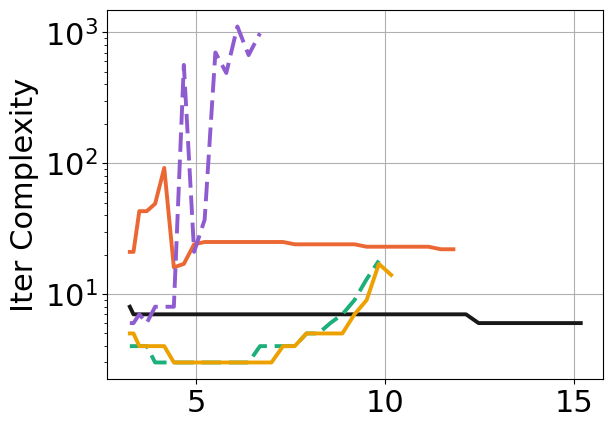

In [155]:
iters_to_conv = {}   # {kappa: {method: int or nan}}

ERR_TOL = 0.05
for kappa in KAPPA_VALUES:
    iters_to_conv[kappa] = iters_to_converge_loss(
        all_summary[kappa], tol_ul=ERR_TOL, tol_ll=10
    )

print(f"Iterations to reach median ‖w−w*‖ < {ERR_TOL:g}  AND  |θ−θ*| < {ERR_TOL:g}"
      f"  (— = not reached in {N_ITERS} iters)\n")
header = f"{'algorithm':<15}" + "".join(f"  κ={k:>6g}" for k in KAPPA_VALUES)
print(header)
print("-" * len(header))


for m in METHODS_RUN:
    iter_comps = []
    kappa_vals = []
    row = f"{m:<15}"
    for kappa in KAPPA_VALUES[9:]:
        v = iters_to_conv[kappa][m]
        row += f"  {'—' if np.isnan(v) else int(v):>8}"
        iter_comps.append(v)

        H = np.diag([kappa, 1.0])
        cond_num = actual_cond_num(W_TRUE, H)
        kappa_vals.append( cond_num )
    plt.plot(kappa_vals, iter_comps,label=m,
             linewidth=2.8,color=COLOURS[m],linestyle=LINESTYLES[m],)
    print(row)
# plt.legend()
plt.ylabel('Iter Complexity')
plt.grid(True)
plt.yscale('log')
plt.show()

In [126]:
def actual_cond_num(wo, H):                                              
      n = len(H)                                                           
      wo_col = wo.reshape(-1, 1)          # (n, 1)
      z_col  = np.zeros((n, 1))           # (n, 1)                         
      z_scalar = np.zeros((1, 1))         # (1, 1)                         
      kkt_mat = np.block([                                                 
          [H,          z_col,    H      ],   # (n, 2n+1)                   
          [z_col.T,   z_scalar, wo_col.T],  # (1, 2n+1)                   
          [H,          wo_col,   0*H    ],   # (n, 2n+1)                   
      ])    
      print(kkt_mat)                                                               
      return np.linalg.cond(kkt_mat)   

kappa = 1
H = np.diag([kappa, 1.0])
print(actual_cond_num(W_TRUE, H))
# print(actual_cond_num())

[[1. 0. 0. 1. 0.]
 [0. 1. 0. 0. 1.]
 [0. 0. 0. 1. 1.]
 [1. 0. 1. 0. 0.]
 [0. 1. 1. 0. 0.]]
3.23606797749979


## Convergence curves

In [59]:
print(all_summary[10][m].keys())

dict_keys(['runs', 'total', 'frac_completed', 'frac_diverged', 'frac_solved', 'median_final_w_err', 'median_final_theta_err', 'median_curve_UL', 'median_curve_LL', 'median_curve_w_err', 'median_curve_theta_err', 'success_curve'])


['PABLO', 'BOME', 'TSP', 'STABLE', 'AAL']


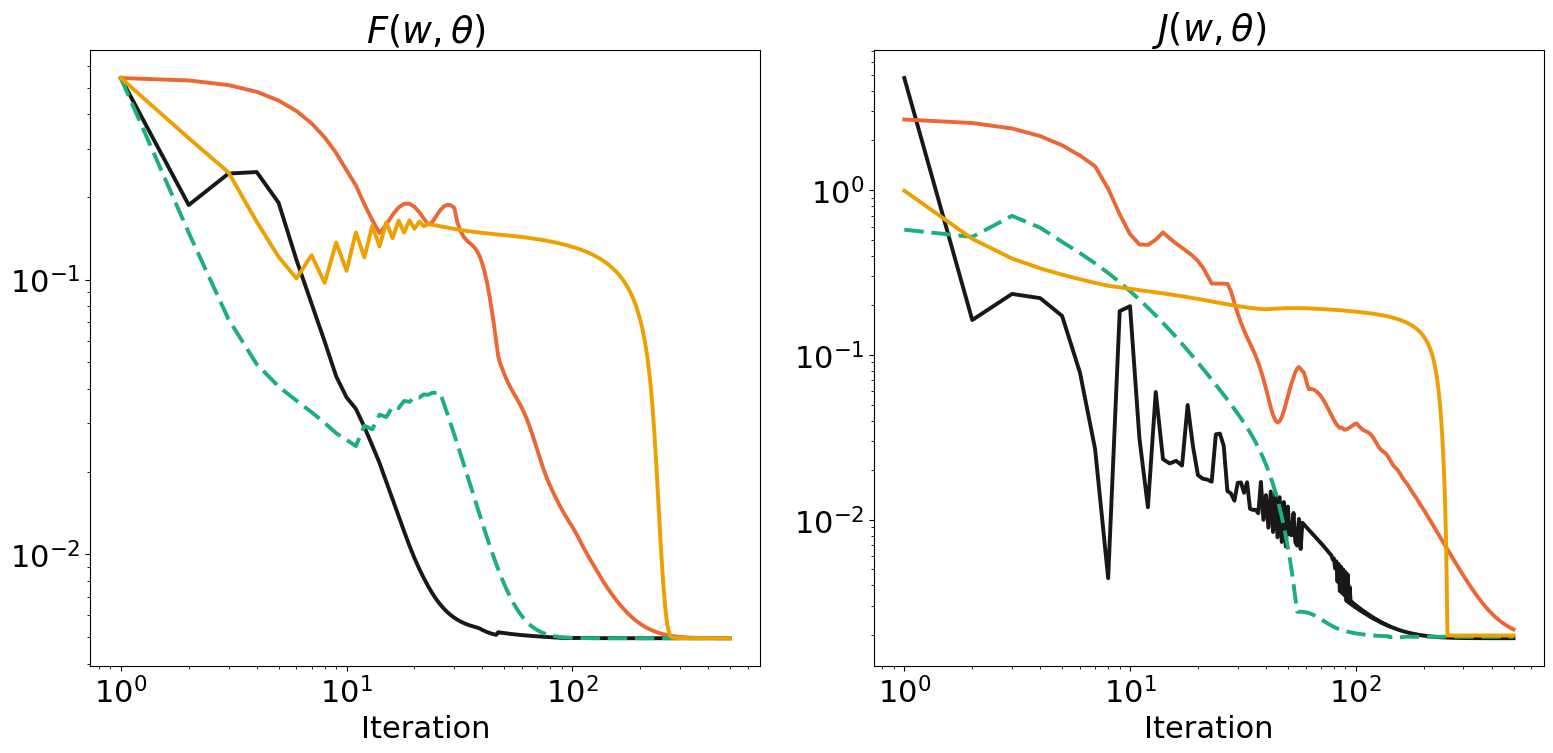

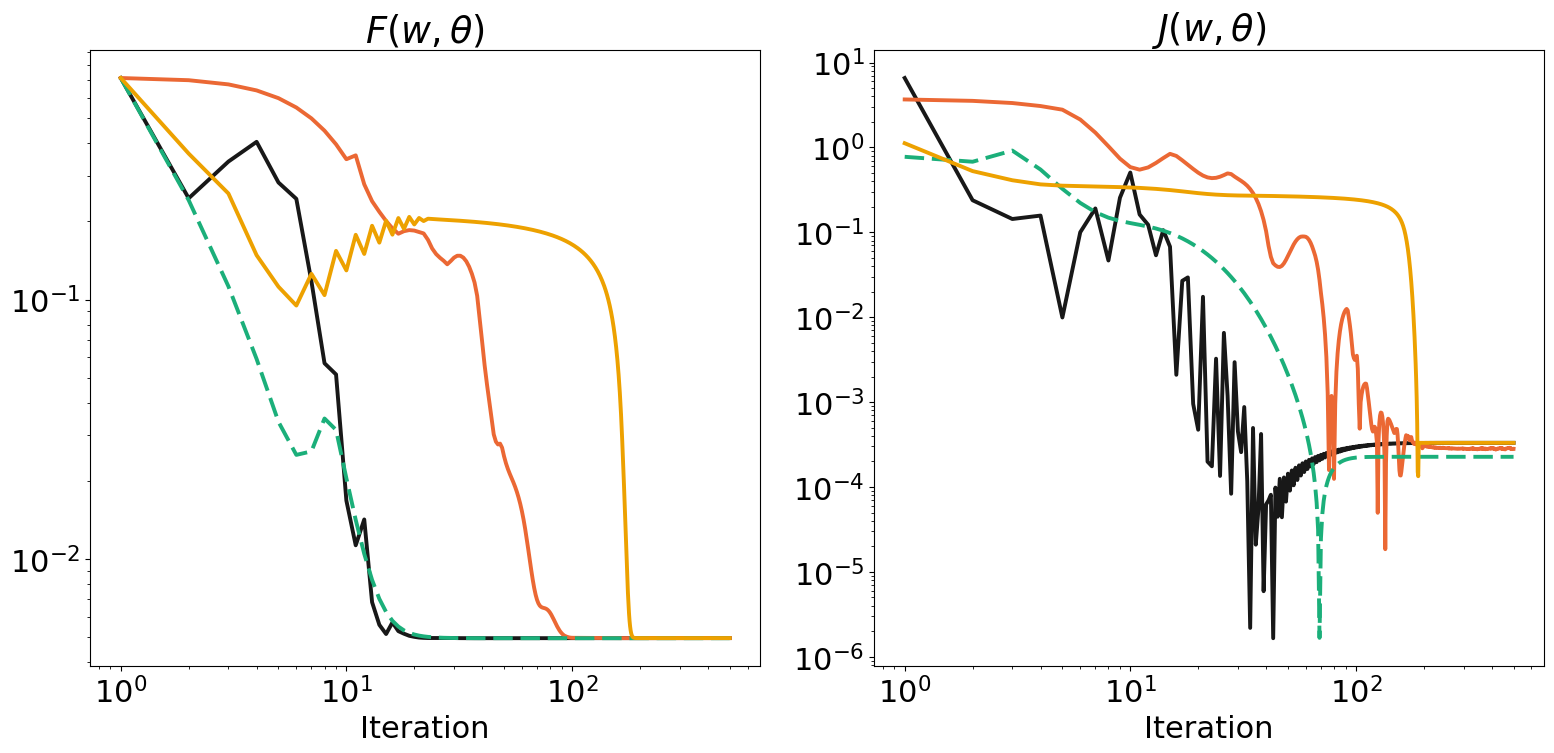

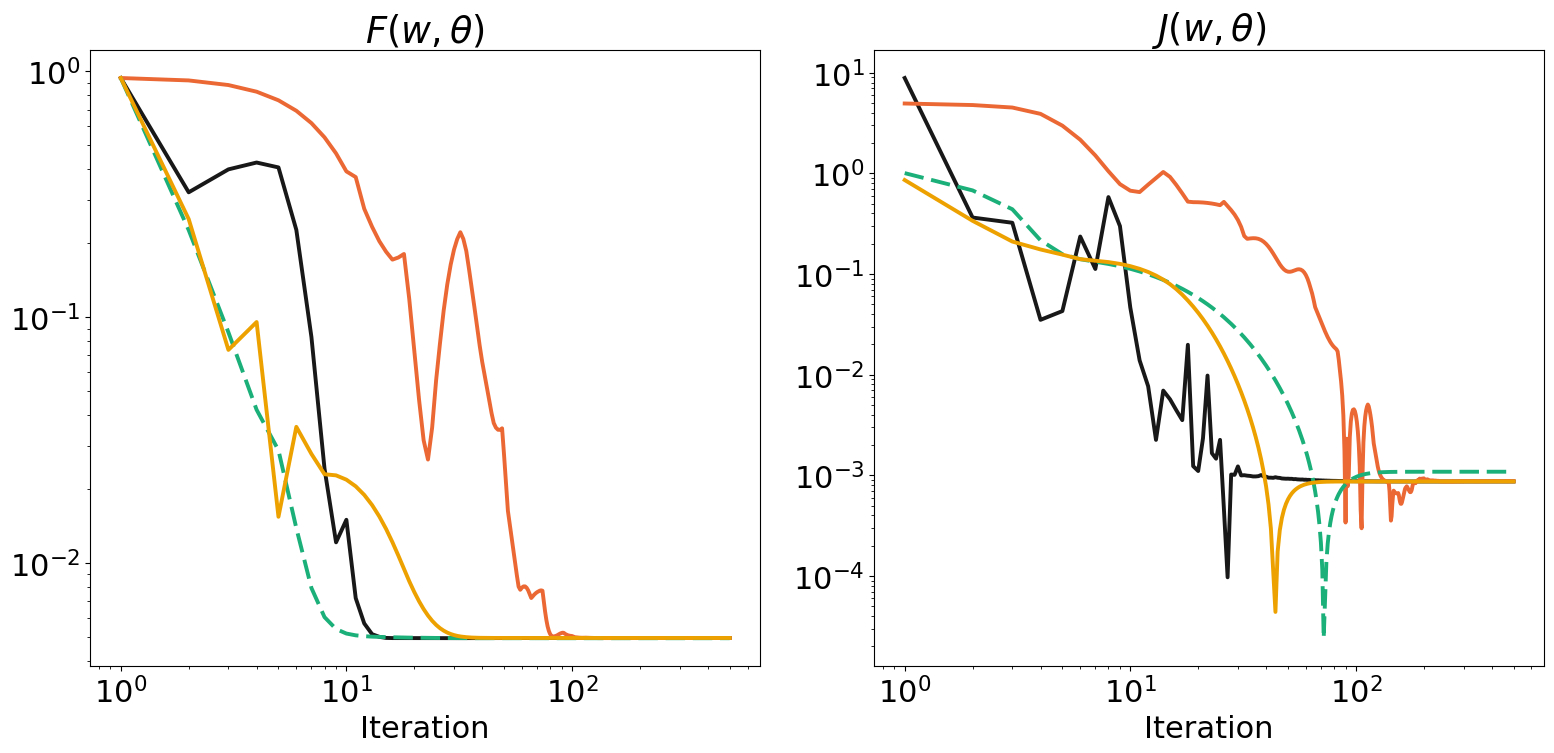

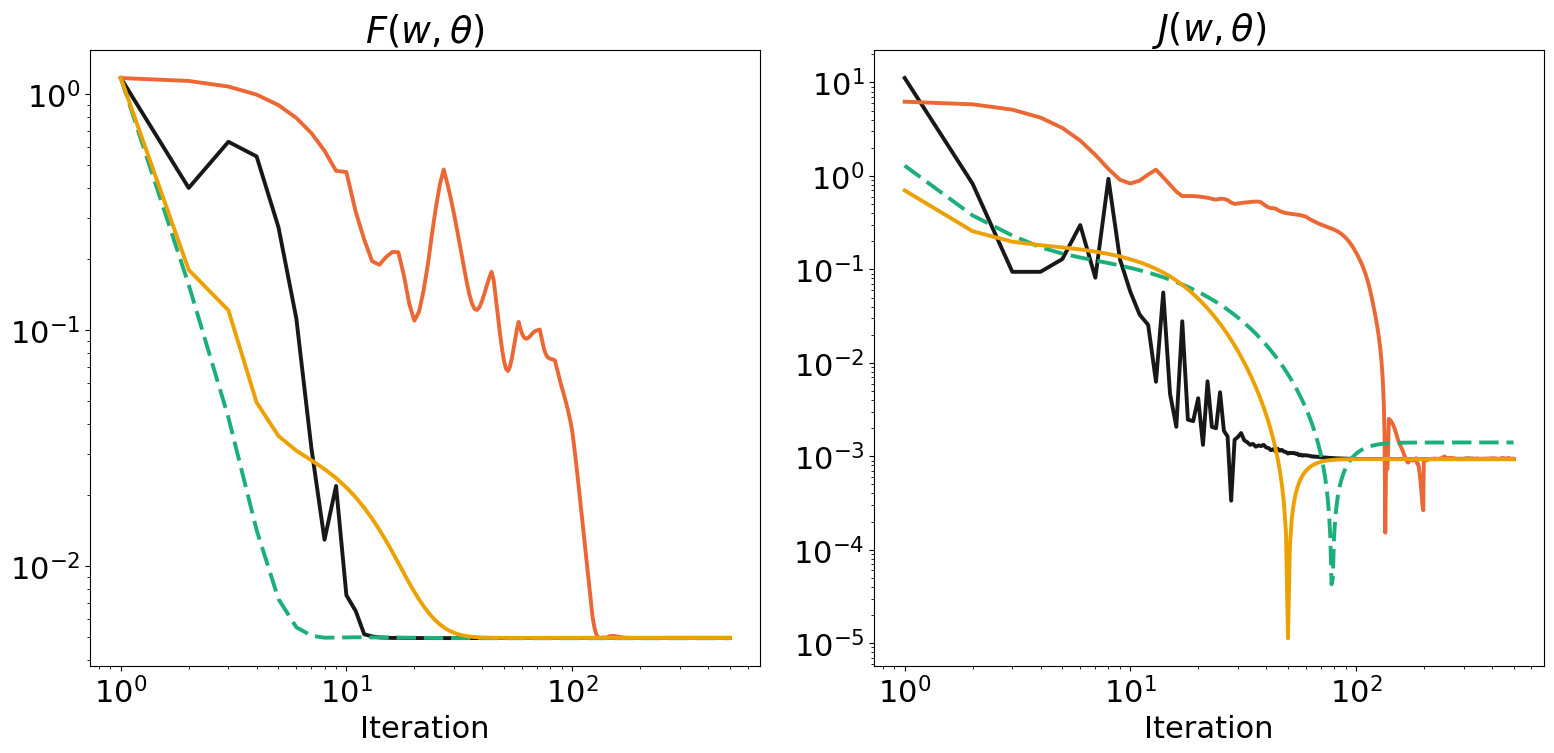

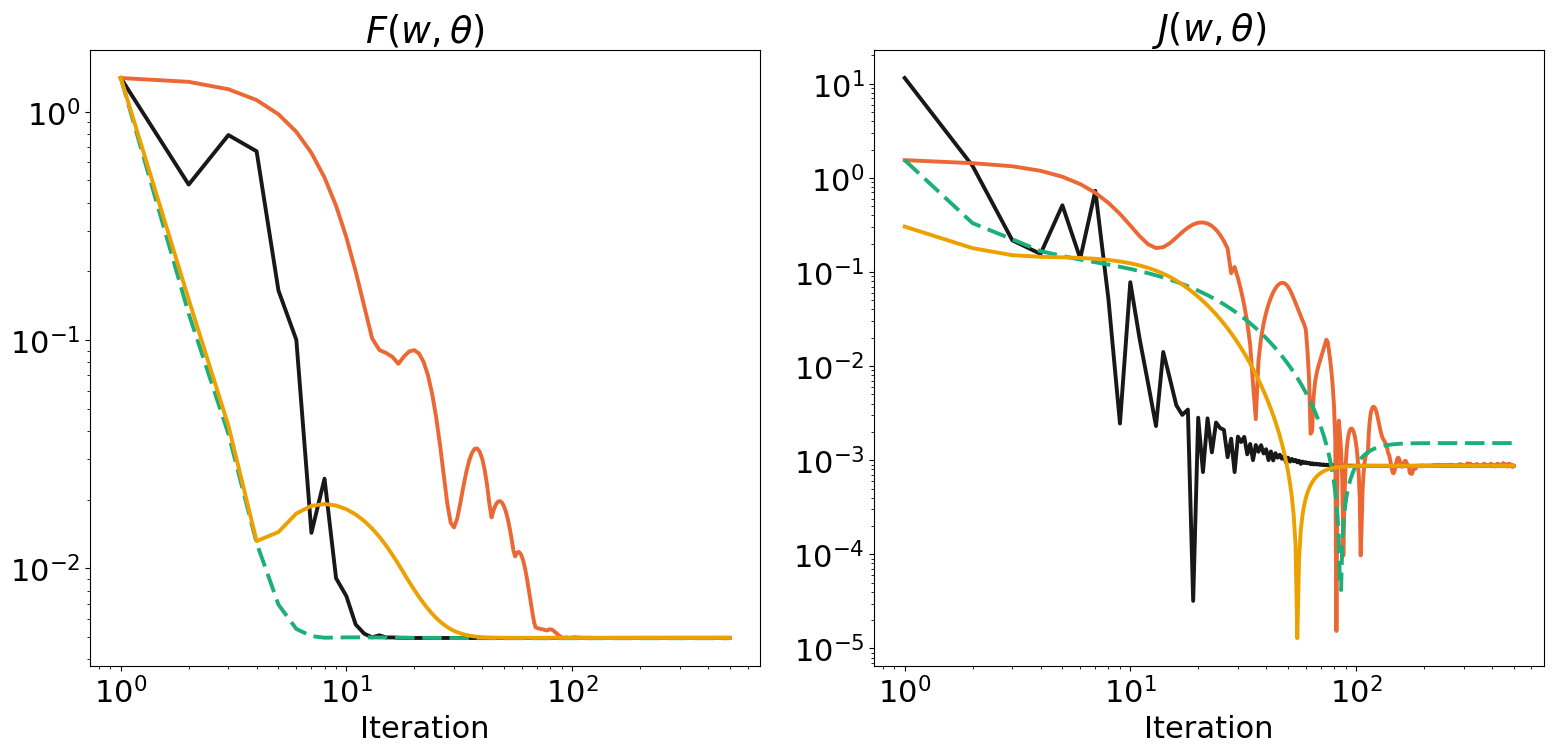

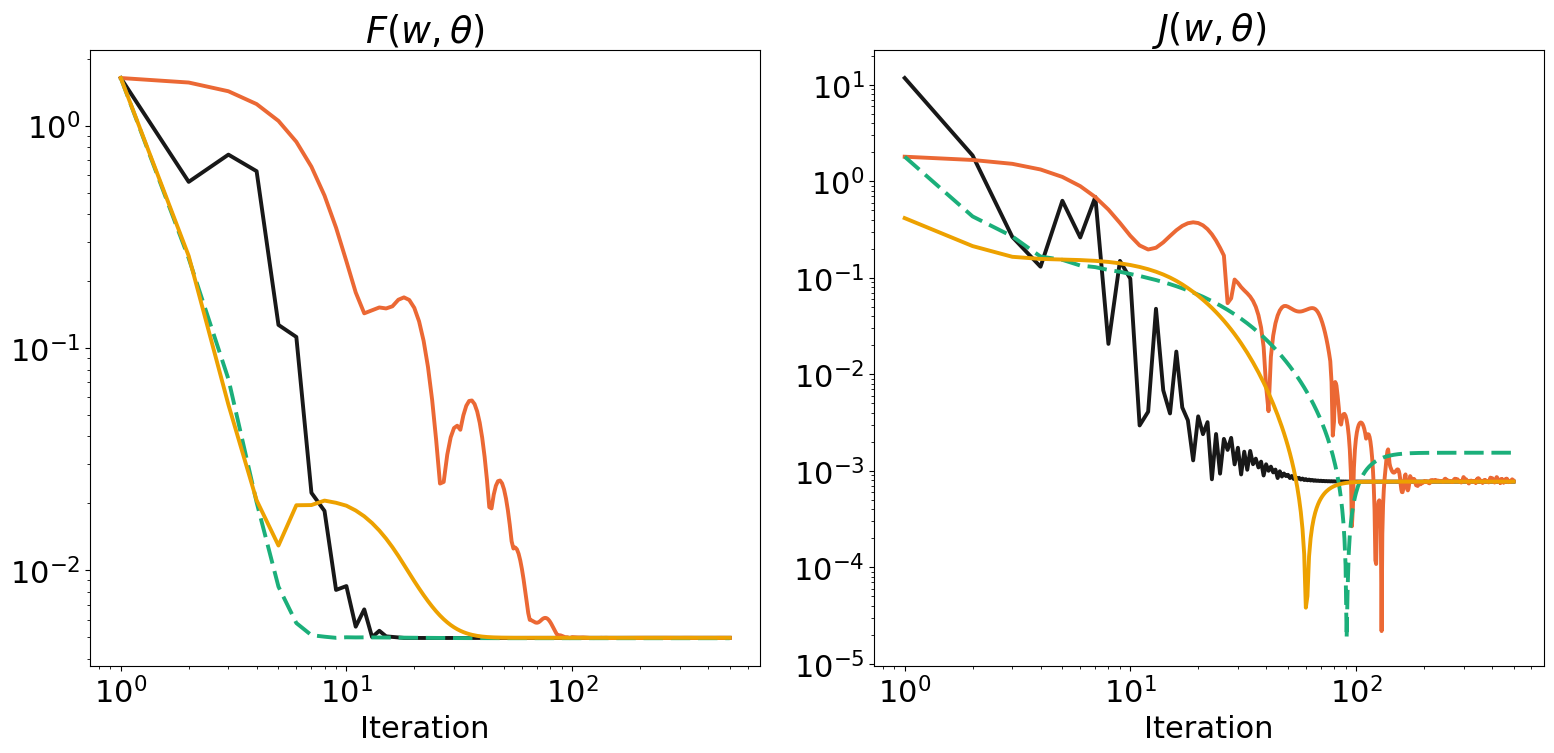

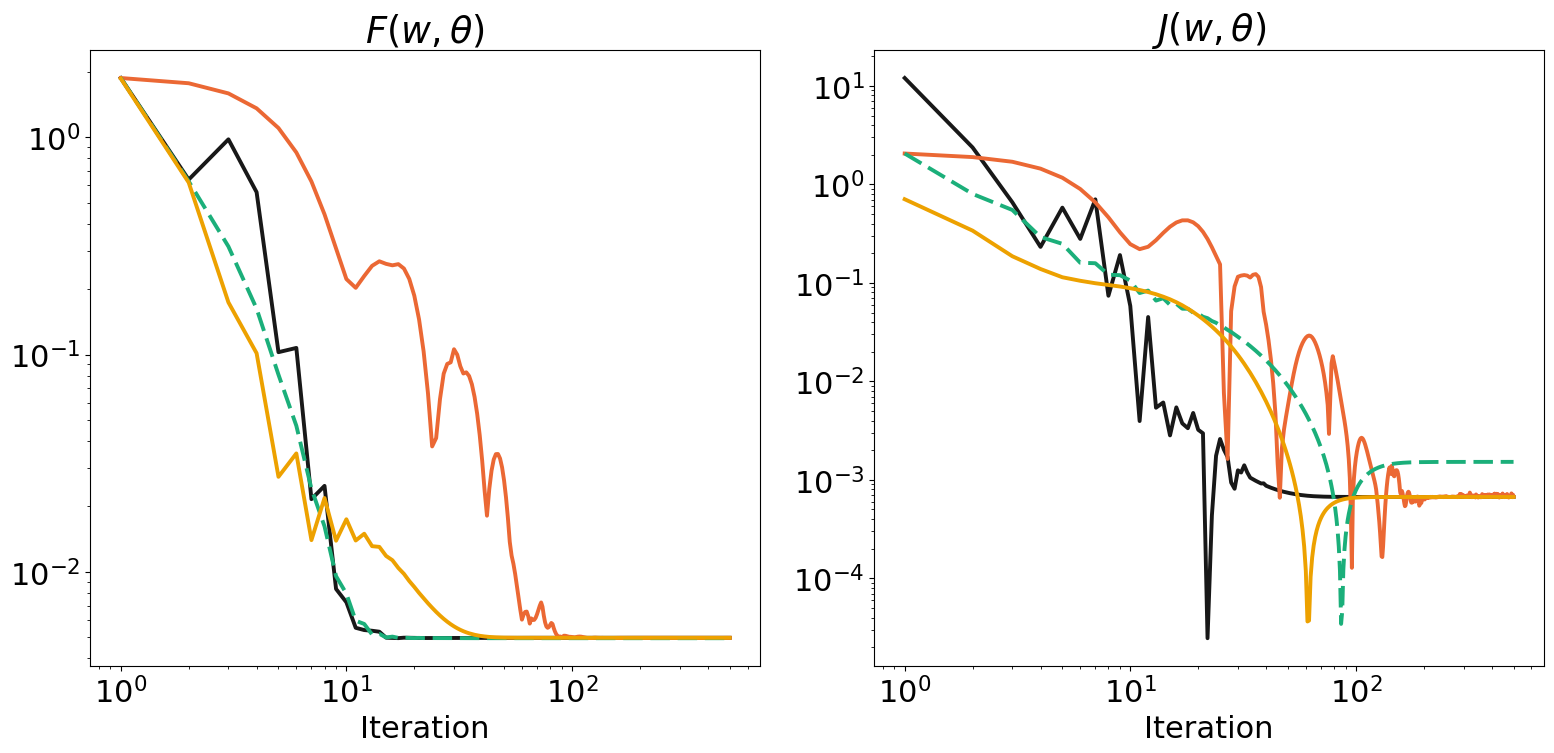

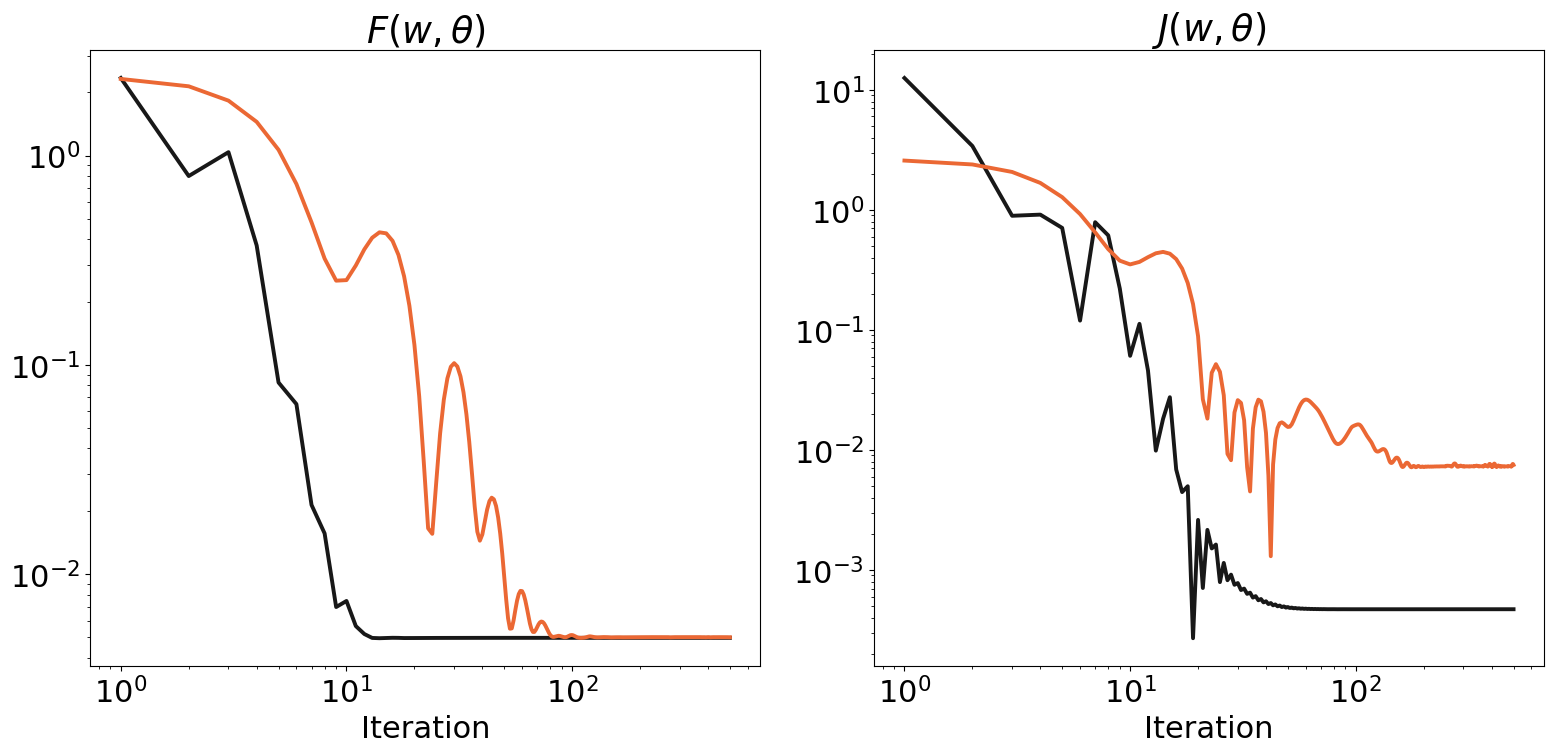

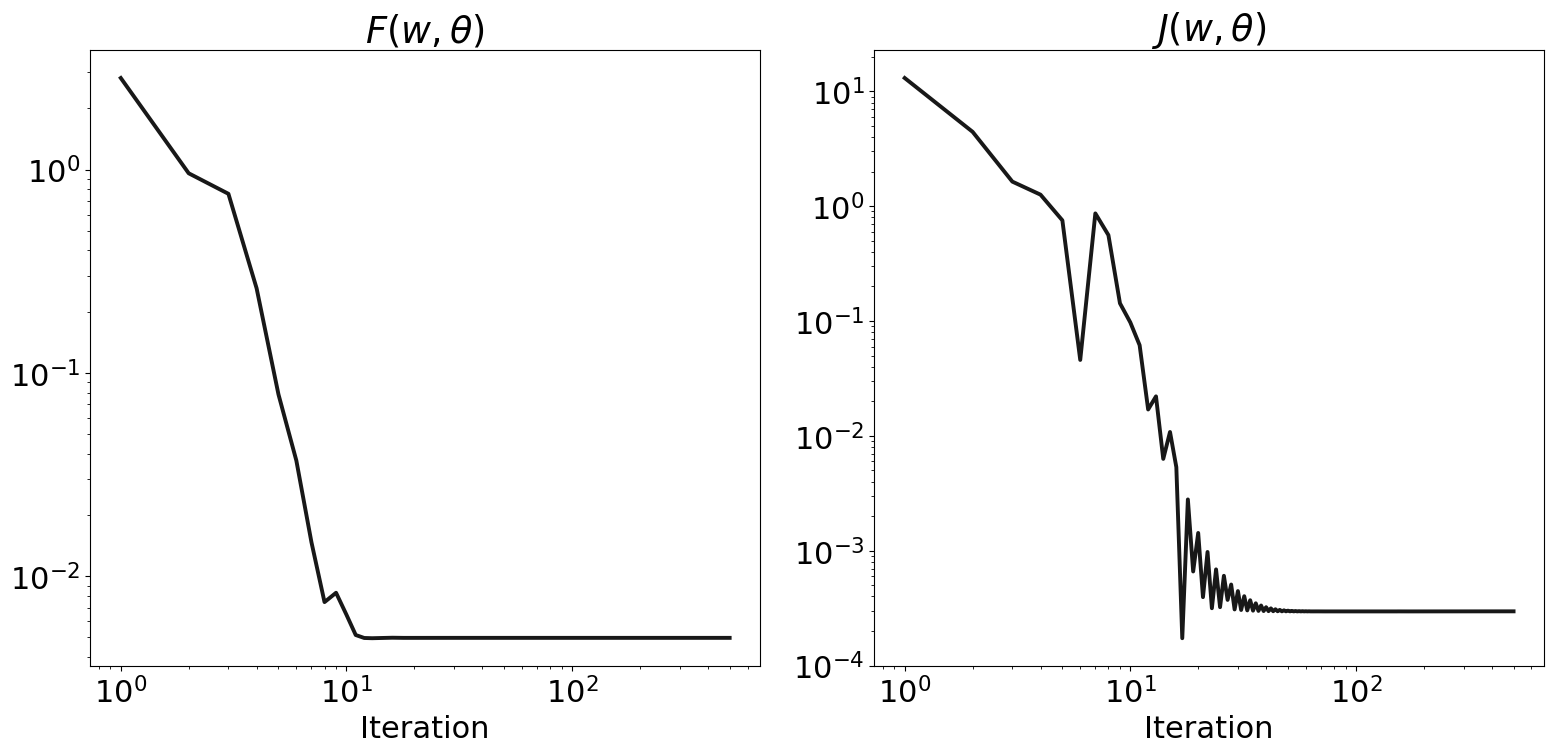

In [107]:

plt.rcParams.update({'font.size': 22})
# if len(KAPPA_VALUES) == 1:
#     axes = axes[None, :]

iters = np.arange(1, N_ITERS + 1)

print(METHODS_RUN)
metrics = [ ("median_curve_UL", r"$F(w,\theta)$"), ("median_curve_LL", r"$J(w,\theta)$") ]

for row, kappa in enumerate(KAPPA_VALUES):
    fig, axes = plt.subplots(
        1, 2, figsize=(16, 8 ), sharex=True,
    )
    for m in METHODS_RUN:
        if m=='AAL': 
            continue
        sm = all_summary[kappa][m]
        for idx, (metric_key, metric_title) in enumerate(metrics):
            if sm[metric_key] is None:
                continue
            axes[idx].semilogy(iters, np.abs(sm[metric_key]),label=m, linewidth=2.8,color=COLOURS[m],linestyle=LINESTYLES[m],)
            axes[idx].set_title(metric_title)
            axes[idx].set_xlabel("Iteration")
            axes[idx].set_xscale("log")
    plt.tight_layout()
    plt.show()


# for row, kappa in enumerate(KAPPA_VALUES):
#     ax_w, ax_th = axes[row]
#     for m in METHODS_RUN:
#         sm = all_summary[kappa][m]
#         if sm["median_curve_w_err"] is None:
#             continue
#         ax_w.semilogy(iters, sm["median_curve_UL"],   label=m, linewidth=2.8,color=COLOURS[m],linestyle=LINESTYLES[m],)
#         ax_th.semilogy(iters, sm["median_curve_LL"], label=m, linewidth=2.8,color=COLOURS[m],linestyle=LINESTYLES[m],)
#     ax_w.axhline(ERR_TOL, color='k', linestyle=':', linewidth=4.8)
#     ax_th.axhline(ERR_TOL, color='k', linestyle=':', linewidth=4.8)
#     # ax_w.set_ylabel(rf'median $\|w_t - w^*\|$  (κ={kappa:g})')
#     # ax_th.set_ylabel(rf'median $|\theta_t - \theta^*|$  (κ={kappa:g})')
#     plt.grid(True)
#     if row == 0:
#         ax_w.legend(ncol=2)

# axes[-1, 0].set_xlabel('iteration')
# axes[0,0].grid(True)
# axes[-1,1].grid(True)
# axes[-1, 1].set_xlabel('iteration')
# fig.suptitle('Convergence — conditioning sweep', y=1.01)
# plt.tight_layout()
# plt.show()

## Save

Writes three files to `results/`:
* `*_iters.csv`   — convergence table  (rows = algorithms, columns = κ values)
* `*_hparams.json` — tuned hyperparameters per (κ, method)
* `*_detail.csv`  — per-start final errors for every (κ, method, w0, θ0)

In [ ]:
os.makedirs("results", exist_ok=True)
k_tag = "_".join(f"{k:g}" for k in KAPPA_VALUES)
tag   = f"ridge_cond_k{k_tag}_n{FULL_N}_it{N_ITERS}"

# 1. Convergence CSV
csv_path = f"results/{tag}_iters.csv"
with open(csv_path, "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["algorithm"] + [f"kappa={k:g}" for k in KAPPA_VALUES])
    for m in METHODS_RUN:
        wr.writerow([m] + [
            ("" if np.isnan(iters_to_conv[k][m]) else int(iters_to_conv[k][m]))
            for k in KAPPA_VALUES
        ])
print(f"Saved: {csv_path}")

# 2. Hyperparameters JSON
hp_path = f"results/{tag}_hparams.json"
with open(hp_path, "w") as fh:
    json.dump(
        {f"kappa={k:g}": {m: hp for m, hp in hps.items()}
         for k, hps in all_hparams.items()},
        fh, indent=2, default=str,
    )
print(f"Saved: {hp_path}")

# 3. Per-start detail CSV
detail_path = f"results/{tag}_detail.csv"
with open(detail_path, "w", newline="") as fh:
    wr = csv.writer(fh)
    wr.writerow(["kappa", "algorithm", "w0", "theta0",
                 "final_w_err", "final_theta_err",
                 "final_ul_loss", "final_ll_loss"])
    for kappa in KAPPA_VALUES:
        for m in METHODS_RUN:
            d  = all_sweep[kappa][m]
            sm = all_summary[kappa][m]
            wo = d["w_opt"]
            to = d["theta_opt"]
            for idx, ((w0, t0), w, th, ul, ll) in enumerate(
                    zip(d["starts"], d["w"], d["theta"], d["ul_loss"], d["ll_loss"])):
                wr.writerow([
                    kappa, m, w0, t0,
                    float(np.linalg.norm(w[-1] - wo)),
                    float(abs(th[-1] - to)),
                    float(ul[-1]),
                    float(ll[-1]),
                ])
print(f"Saved: {detail_path}")

print("\nDone.")